In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import sparse

import scanpy as sc
import cafe


output = Path("./output/26.10.19-time_methods")
output.mkdir(parents=True, exist_ok=True)


INFO                                                                                                                                                                                                    
             ██████╗ █████╗ ███████╗███████╗                                                                                                                                                            
           ██╔════╝██╔══██╗██╔════╝██╔════╝                                                                                                                                                             
           ██║     ███████║█████╗  █████╗                                                                                                                                                               
           ██║     ██╔══██║██╔══╝  ██╔══╝                                                                                                                                                           

INFO      Version: 0.2.1                                                                                                                                                                                


## Read simulated data

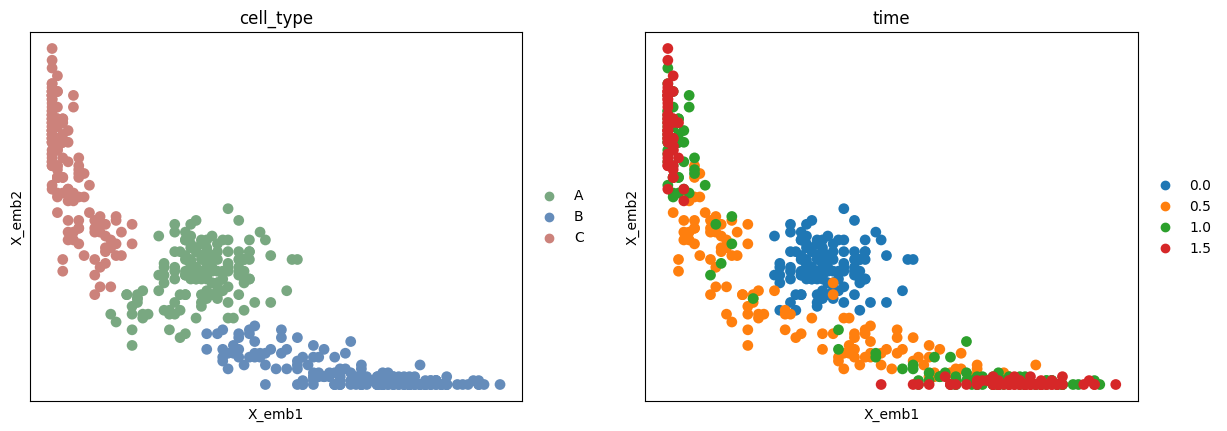

AnnData object with n_obs × n_vars = 500 × 2
    obs: 'time', 'time_raw', 'simulation_id', 'cell_type', 'split'
    var: 'transcription_rate', 'splicing_rate', 'mrna_decay_rate', 'translation_rate', 'protein_decay_rate', 'dyngen_id'
    uns: 'proposed_milestone_network', 'regulatory_network', 'simulation', 'cafe', 'id', 'cell_type_colors', 'time_colors'
    obsm: 'X_emb'
    layers: 'Ms', 'Mu', 'protein', 'spliced', 'unspliced'

In [2]:
adata = sc.read_h5ad("./output/26.10.14-time_strategy/dyngen_synthetic_dataset.h5ad")

# transform Anndata to FateAnnData
fadata = cafe.data.FateAnnData.from_anndata(adata)

# add prior information
cluster_key = "cell_type"
time_key = "time"
basis = "X_emb"
fadata.add_prior_information(time_key=time_key, cluster=cluster_key, basis=basis)

# add cluster and time color.
palette = {"A": "#79a881", "B": "#658cba", "C": "#cc827b"}
times = sorted(fadata.obs[time_key].unique())
fadata.obs[time_key] = pd.Categorical(fadata.obs[time_key], categories=times, ordered=True)
fadata.uns[f"{cluster_key}_colors"] = list(palette.values())
sc.pl.embedding(fadata, basis=basis, color=[cluster_key, time_key])
fadata

## Run methods

### referenced mapping

In [3]:
reference = {}
for t1, t2 in zip(times[:-1], times[1:]):
    source = adata.obs.loc[adata.obs[time_key] == t1, "simulation_id"].to_numpy()
    target = adata.obs.loc[adata.obs[time_key] == t2, "simulation_id"].to_numpy()
    reference[t1, t2] = sparse.csr_matrix(source[:, None] == target[None, :], dtype=float)

wrapper_kwargs = {"flow_threshold": 0.1, "relative_threshold": 0.3}
fadata.add_model_name("reference_timezone")
fadata.add_trajectory_time(reference, strategy="timezone", **wrapper_kwargs)


### Waddington-OT

In [4]:
wot = cafe.method.FateMethod("waddingtonot", backend_name="conda")
wot.infer_trajectory(
    fadata,
    id="waddingtonot_timezone",
    parameters={
        "repreprocess": False,
        "model_kwargs": {"local_pca": 0, "growth_iters": 1, "epsilon": 0.05},
        "trajectory_kwargs": {"strategy": "timezone", **wrapper_kwargs},
    },
)
fadata.get_milestone_wrapper().milestone_network

INFO     |- method backend loaded: CondaBackend: waddingtonot in conda env 'waddingtonot'                                                                                                               


INFO     |- MilestoneNetwork: 2 edges                                                                                                                                                                   
           from to  length  directed                                                                                                                                                                    
         0    A  B     1.5      True                                                                                                                                                                    
         1    A  C     1.5      True                                                                                                                                                                    


INFO     |- method infer trajectory successfully: CondaBackend: waddingtonot in conda env 'waddingtonot'                                                                                                


,from,to,length,directed
0,A,B,1.5,True
1,A,C,1.5,True


### Moscot

In [5]:
moscot = cafe.method.FateMethod("moscot", backend_name="conda")
moscot.infer_trajectory(
    fadata, 
    id="moscot_timezone", 
    parameters={
    "repreprocess": False,
    "prepare_kwargs": {"joint_attr": {"attr": "X", "tag": "point_cloud"}},
    "solve_kwargs": {"epsilon": 0.05, "scale_cost": "median", "device": "cpu", "max_iterations": 10000, "threshold": 1e-4},
    "trajectory_kwargs": {"strategy": "timezone", **wrapper_kwargs},
})
fadata.get_milestone_wrapper().milestone_network

INFO     |- method backend loaded: CondaBackend: moscot in conda env 'moscot'                                                                                                                           


INFO     |- MilestoneNetwork: 2 edges                                                                                                                                                                   
           from to  length  directed                                                                                                                                                                    
         0    A  B     1.5      True                                                                                                                                                                    
         1    A  C     1.5      True                                                                                                                                                                    


INFO     |- method infer trajectory successfully: CondaBackend: moscot in conda env 'moscot'                                                                                                            


,from,to,length,directed
0,A,B,1.5,True
1,A,C,1.5,True


## compare transport matrix

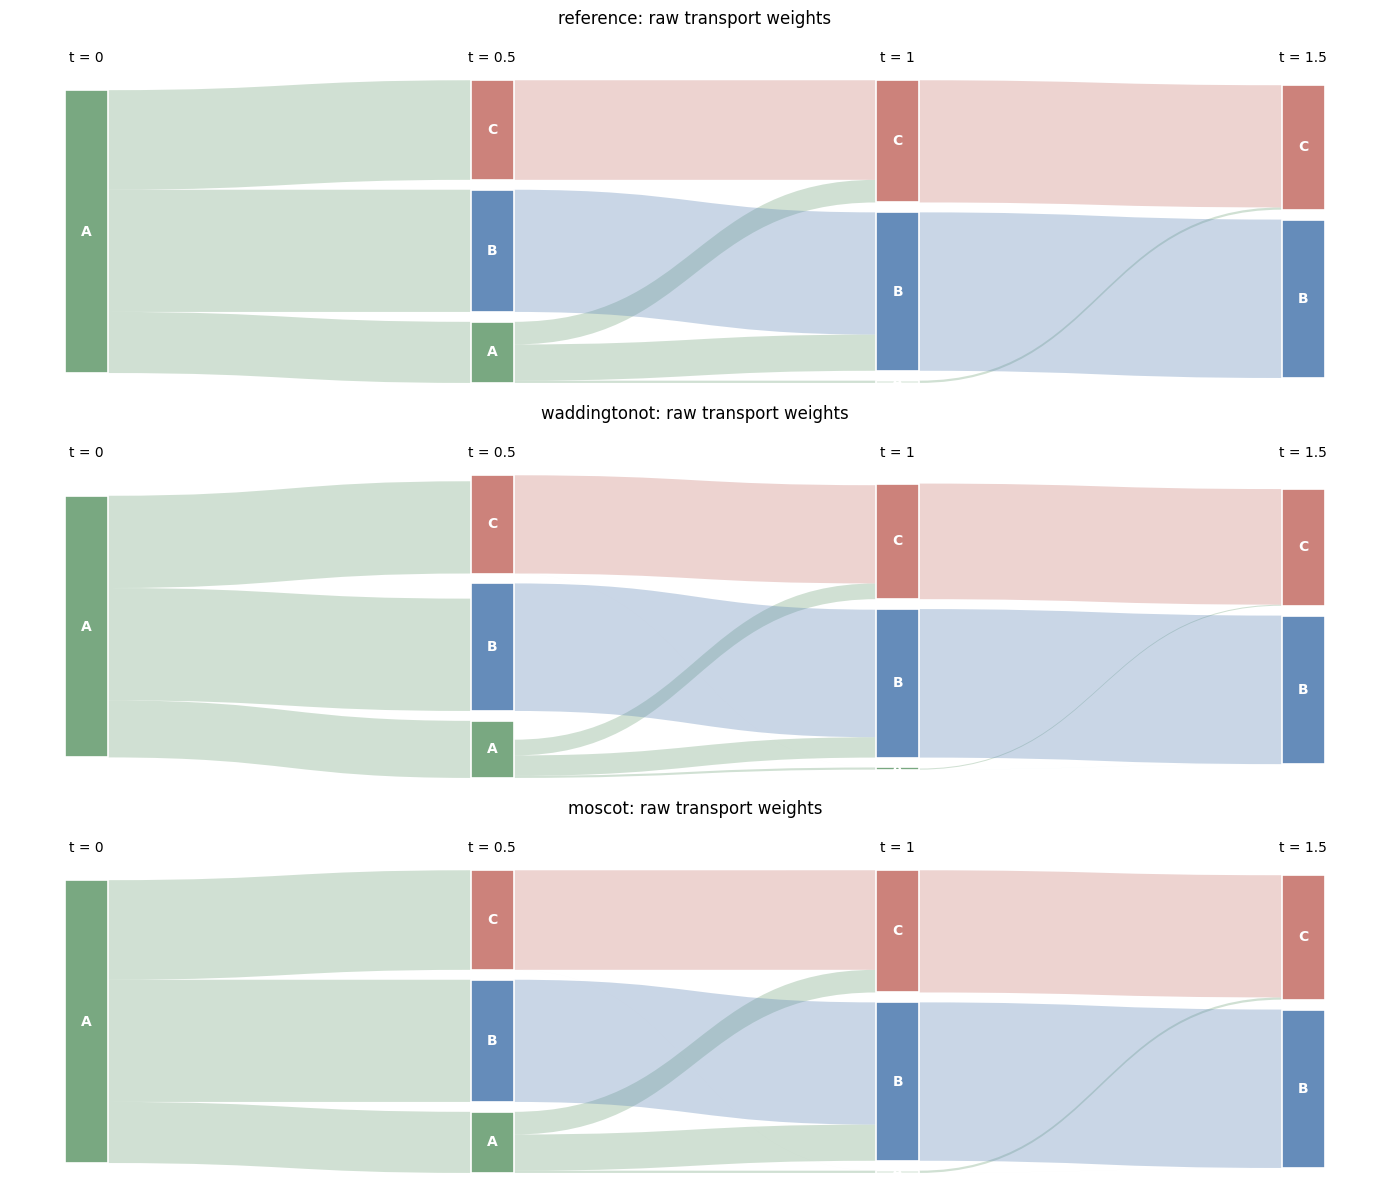

In [6]:
sources = {"reference": reference, **{
    name: fadata.get_raw_wrapper_dict(f"{name}_timezone")["tmaps"]
    for name in ["waddingtonot", "moscot"]
}}
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
for ax, (name, tmaps) in zip(axes, sources.items()):
    cafe.plot.plot_sankey(adata, tmaps, time_key="time", cluster_key="cell_type", palette=palette,
                          ax=ax, title=f"{name}: raw transport weights")
fig.savefig(output / "sankey_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## compare the graph and trajectory 

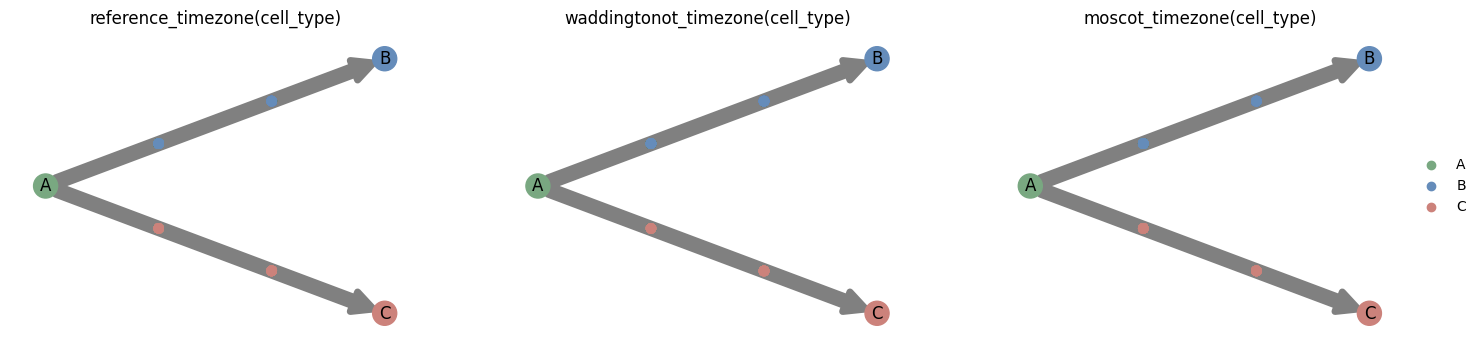

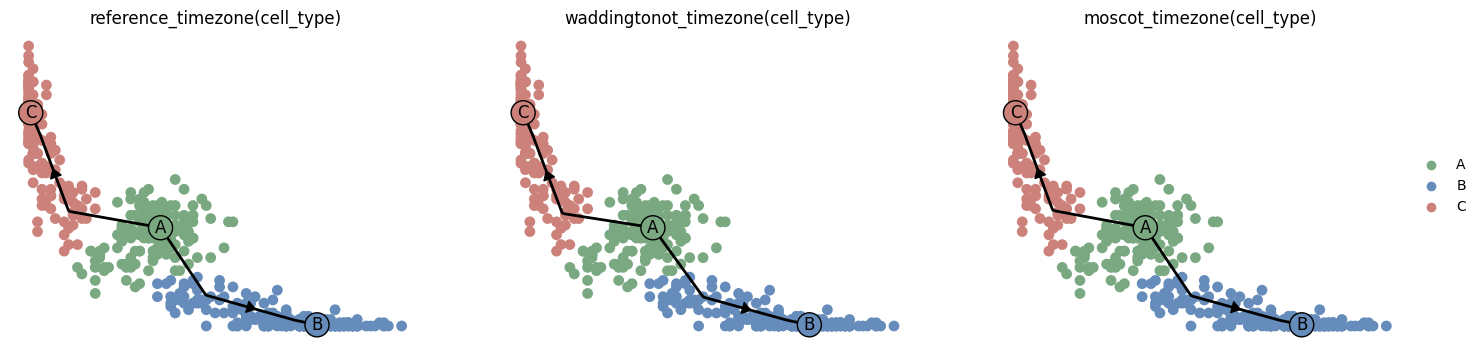

In [7]:
models = [f"{name}_timezone" for name in sources]
cafe.plot.plot_graph(fadata, model_name=models, color=cluster_key, layout_rankdir="LR", figsize=(18, 4),
                     save=str(output / "network_timezone.png"))
plt.show()
cafe.plot.plot_trajectory(fadata, model_name=models, basis=basis, color=cluster_key,
                          show_milestone_labels=True, figsize=(18, 4),
                          save=str(output / "trajectory_timezone.png"))
plt.show()


## Notes

- 同一输入、相邻时间、平方欧氏代价与中位数缩放；正则化取 0.05。WOT 使用原生非平衡边际设置，Moscot 首轮使用平衡边际，因此不是完全同目标函数的性能排名。
- 未提供增殖/凋亡评分；WOT 的增长初值为 1。WOT OTModel 不暴露逐窗口收敛标志，记为未知，不用非空输出冒充收敛。
- 两方法统一使用上述 wrapper 阈值；原始未剪枝权重保留在结果中。OT 质量跨方法不可直接解释为细胞数量。
- timezone 进度由时间定义，不作为方法准确性指标。
